# Homework 6: Chance Constraints

## 1. Radar Rainfall Problem

Radar can be used to estimate rainfall rates based on the reflectivity of raindrops. The relationship between radar reflectivity $Z$ (mm$^6$/m$^3$) and rainfall rate $R$ (mm/hr) follows a power law: $Z = aR^b$ where $a$ and $b$ are constants. Radar reflectivity is a function of the raindrop size distribution: $Z = E[ND^6]$ where $N$ is the number of raindrops per unit volume (mm$^{-1}$m$^3$) and $D$ is a random variable representing the raindrop diameter (mm). It is often assumed that the diameters of raindrops follow an exponential distribution: $f_D(d) = \lambda e^{-\lambda d}$, which has a domain of (0,$\infty$).

a. Knowing $Z = E[ND^6]$ and $f_D(d) = \lambda e^{-\lambda d}$, calculate Z as a function of $N$ and $\lambda$. Hint: use the definition of the gamma function $\Gamma(\alpha) = \int_0^\infty  x^{\alpha-1} e^{-x} dx = (\alpha-1)!$ and let $x=\lambda d$.

b. Marshall and Palmer (1948) found that the raindrop density $N$ is approximately constant at 8000 mm$^{-1}$ m$^{-3}$ regardless of the rainfall rate. However, the parameter $\lambda$ of the raindrop size distribution varies across events. Assume $\lambda$ also follows an exponential distribution, but with a lower bound of 1 and parameter $\beta=0.5$: $f(\lambda) = \beta e^{-\beta (\lambda-1)}$. Given your answer to part (a) and the pdf of $\lambda$, find the pdf of reflectivity $Z$ across rainfall events. What is the lower and upper bound of $Z$?

Reference:
Marshall, J. S., \& Palmer, W. M. K. (1948). The distribution of raindrops with size. *Journal of Atmospheric Sciences*, *5*(4), 165-166.

c. Given your answer to part (b) and the fact that $Z = aR^b$, find the pdf of rainfall rates $R$ across events when $a=200$ and $b=1.6$. What is the lower and upper bound of $R$?

$\color{red}{\text{Enter your derivations for the above or upload them as a separate document.}}$

d. Write a class in Python for the rainfall rate distribution with methods to calculate its pdf, cdf, ppf, moments and central moments. To avoid division by 0 errors, use a lower bound of 0.001 on the rainfall rate instead of 0, but use the upper bound calculated in part (c). Using your functions, calculate the mean, median, variance and 99.9 percentile of the distribution.

$\color{red}{\text{Complete the code below to answer this question.}}$

In [14]:
!pip install pynverse

In [15]:
import scipy.integrate as integrate
from pynverse import inversefunc
from math import gamma
import numpy as np

class RainfallRateDist:
    def __init__(self, N, beta, a, b):
        self.N = N
        self.beta = beta
        self.a = a
        self.b = b
        self.UB = (720*N/a)**(1/b)

    def pdf(self, x):
        fx = ((self.beta*self.b)/6 * ((720*self.N)/self.a)**(1/6) * x**((-self.b/6) - 1) * np.exp(-self.beta*((720*self.N/(self.a*(x**self.b)))**(1/6)-1)))

        return fx

    def cdf(self, x):
        # integrate pdf from 0.001 to x (this is complete)
        return integrate.quad(lambda x: self.pdf(x), 0.001, x)[0]

    def ppf(self, q):
        # invert cdf (this is complete)
        cdf = lambda x: self.cdf(x)
        ppf = inversefunc(cdf, domain=[0.001, self.UB])
        return ppf(q)

    def moment(self, m):
        # integrate x^m * f(x) from 0.001 to UB (this is complete)
        return integrate.quad(lambda x: (x**m * self.pdf(x)), 0.001, self.UB)[0]

    def central_moment(self, m):
        # integrate (x-mu)^m * f(x) from 0.001 to UB (this is complete)
        mu = self.moment(1)
        return integrate.quad(lambda x: ((x-mu)**m * self.pdf(x)), 0.001, self.UB)[0]

# initialize random variable R (this is complete)
N = 8000
beta = 0.5
a = 200
b = 1.6
R = RainfallRateDist(N, beta, a, b)

from scipy.optimize import brentq
R.ppf = lambda q: brentq(lambda x: R.cdf(x) - q, 0.001, R.UB)

# comute the mean, median, variance and 99.9th percentile of R (complete these equations)
mean_r = R.moment(1)
median_r = R.ppf(0.5)
var_r = R.central_moment(2)
q_999_r = R.ppf(0.999)

# print values (this is complete)
print("Mean of r: %d (mm/hr)" % mean_r)
print("Median of r: %d (mm/hr)" % median_r)
print("Variance of r %d (mm/hr)^2 " % var_r)
print("99.9 percentile of r: %d (mm/hr)" % q_999_r)

Mean of r: 89 (mm/hr)
Median of r: 23 (mm/hr)
Variance of r 18538 (mm/hr)^2 
99.9 percentile of r: 607 (mm/hr)


$\color{red}{\text{e. Complete the code below to plot the pdf and cdf of the rainfall rate distribution on a 2-panel figure.}}$

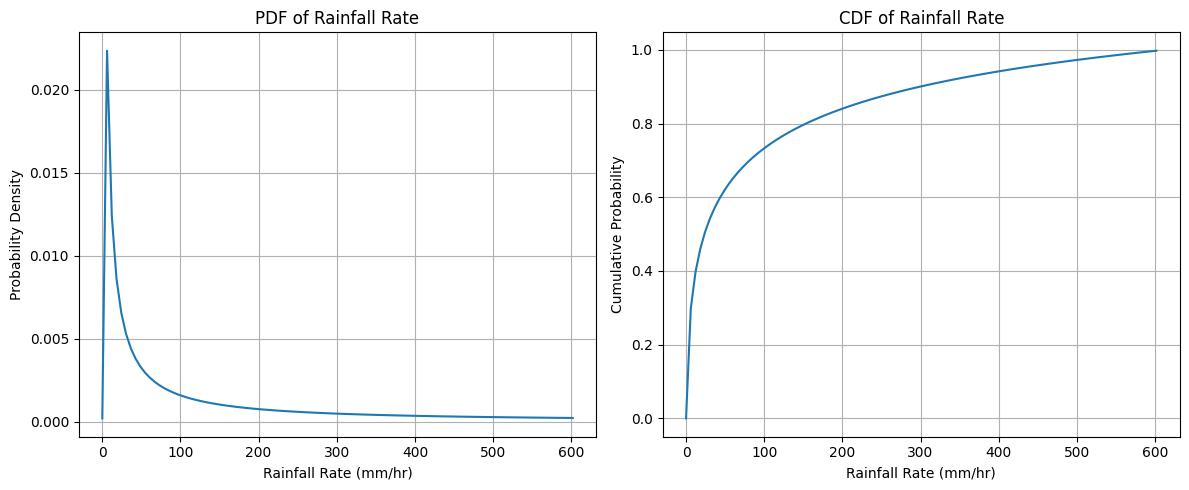

In [16]:
import matplotlib.pyplot as plt

# plot pdf and cdf of R over this domain of r
r = np.arange(0.001,q_999_r,(q_999_r-0.001)/100)

pdf_values = [R.pdf(x) for x in r]
cdf_values = [R.cdf(x) for x in r]

fig,ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].plot(r, pdf_values)
ax[0].set_title("PDF of Rainfall Rate")
ax[0].set_xlabel("Rainfall Rate (mm/hr)")
ax[0].set_ylabel("Probability Density")
ax[0].grid()

ax[1].plot(r, cdf_values)
ax[1].set_title("CDF of Rainfall Rate")
ax[1].set_xlabel("Rainfall Rate (mm/hr)")
ax[1].set_ylabel("Cumulative Probability")
ax[1].grid()

plt.tight_layout()
plt.show()


## 2.  Air Quality Problem

This is a modification from Prof. Culver of a problem in Haith, D. A. (1982). Environmental systems optimization.

Burning Eyes County has an air pollution problem. The air pollutant KOF, which is emitted from three major sources in the county, has been declared a hazard to health by the state environmental regulatory agency. Emissions of KOF from the three sources are given in Table 1.

| Source | Emissions (kg/day) | Stack Height (m) | Removal Cost (\$/kg) |
| ------ | ------------------ | ---------------- | -------------------- |
| 1      | 34,560             | 50               | 0.020                |
| 2      | 172,800            | 200              | 0.045                |
| 3      | 103,680            | 30               | 0.060                |

Air pollution limits are set assuming class B stability with a 1.2 m/s mean wind speed at a 10 m high anemometer and slight daytime insolation. Five ground level locations (receptors) in the county have been selected as places where health effects are most important. At each of these locations, an ambient air quality standard for KOF has been set at 150 $\mu g/m^3$. The coordinates of sources and receptors are given in Table 2 (x-y coordinates in km, $x$-axis parallel to wind direction).

| Sources | Receptors |
| ------- | --------- |
| (5, 7)  | (6, 1.5)  |
| (7, 5)  | (8, 7)    |
| (8, 5)  | (10, 3)   |
|         | (12.5, 6) |
|         | (15.5, 5) |

Using the Gaussian plume model and a linear program, determine how much each source should reduce their KOF emissions by to meet the air quality standard at all receptors at the lowest cost.

In [17]:
!pip install gurobipy

In [18]:
import numpy as np
import gurobipy as gp
from gurobipy import GRB
import scipy.stats as ss

In class we determined the mathematical formulation of this problem. First, we defined our notation.

Parameters:
* $U^a$ = wind speed at anemometer (m/s)
* $U^h_s$ = wind speed at source $s$ located at height $h$ (m/s)
* $H^a$ = height of anemometer
* $H_s$ = height of smoke stack at source s
* $Qinit_s$ = current emission rate of pollutant from source $s$ (g/s)
* $cost_s$ = \$/g of pollutant treated at source $s$
* $x_s$ = x-coordinate of source s (km)
* $y_s$ = y-coordinate of source s (km)
* $x_r$ = x-coordinate of receptor r (km)
* $y_r$ = y-coordinate of receptor r (km)
* $\Delta x(s,r)$ = distance along x-axis between source $s$ and receptor $r$ (km)
* $\Delta y(s,r)$ = distance along y-axis between source $s$ and receptor $r$ (m)
* $\sigma_y(s,r)$ = dispersion of pollutant from source $s$ along y-axis at distance $\Delta x(s,r)$ from source (m)
* $\sigma_z(s,r)$ = dispersion of pollutant from source $s$ along z-axis at distance $\Delta x(s,r)$ from source (m)

Decision variables:
* $Qfinal_s$ = emission rate of pollutant from source $s$ needed to meet air quality standard

Optimization Problem:
\begin{align}
\text{Minimize} &\quad \sum_{s=1}^{S} cost_s \times (Qinit_s - Qfinal_s)\\
\text{s.t.} &\quad \sum_{s=1}^{S} T_{s,r} \times Qfinal_s \leq 0.00015 g \quad \forall r \in R\\
& \quad Qfinal_s \geq 0 \quad \forall s \in S\\
\text{where} &\\
& T_{s,r} = \frac{\exp\Big(-\Big[\frac{\Delta y(s,r)^2}{2\sigma_y(s,r)^2} + \frac{H_s^2}{2\sigma_z(s,r)^2}\Big]\Big)}{\pi U^h_s \sigma_y(s,r) \sigma_z(s,r)}\\
& U^h_s = U^a \Bigg(\frac{H_s}{H^a}\Bigg)^p\\
& \Delta y(s,r) = |1000 (y_r - y_s) |\\
& \sigma_y(s,r) = a\Delta x(s,r)^{b+c\ln(\Delta x(s,r))}\\
& \sigma_z(s,r) = d\Delta x(s,r)^{e+f\ln(\Delta x(s,r))}\\
& \Delta x(s,r) = \max(0, x_r - x_s)\\
& a,b,c,d,e,f,p \text{ are coefficients defined by the wind class}
\end{align}

The wind class coefficients are defined as follows:  

| Stability Class	| a |	b | c | d | e | f | p | Applicable Range |
| --------------- | - | - | - | - | - | - | - | ---------------- |
| A | 209.6 | 0.8804 | -0.006902 | 310.4 | 1.773 | 0.1879 | 0.15 | 0.1 < x < 0.45 km |
| A | 209.6 | 0.8804 | -0.006902 | 453.9 | 2.117| 0.0	| 0.15 | 0.45 < x < 3.1 km |
| B	| 154.7	| 0.8932 | -0.006271 | 109.8 | 1.064	| 0.01163	| 0.15 | 0.1 < x < 32 km |
| C	| 103.3	| 0.9112 | -0.004845 | 61.14 | 0.9147	| 0.0	| 0.2 | 0.1 < x < 100 km |
| D	| 68.28 |	0.9112 | -0.004845 | 30.38 | 0.7309 | -0.03200 | 0.25 | 0.1 < x < 100 km |
| E	| 51.05 | 0.9112 | -0.004845 | 21.14 | 0.6802	| -0.04522 | 0.4 | 0.1 < x < 100 km |
| F	| 33.96	| 0.9112 | -0.004845 | 13.72 | 0.6584 | -0.05367 | 0.6 | 0.1 < x < 100 km |




First we defined the parameters. Then, we computed the transfer coefficients between all sources and receptors. Finally, we set up and solved the linear programming problem. $\color{red}{\text{The code for this is repeated below. It is complete.}}$

In [19]:
#################### Parameters ####################
# x and y coordinates (km) of sources and receptors
source_coords = np.array([[5,7],
                 [7,5],
                 [8,5]])
nSources = len(source_coords)

receptor_coords = np.array([[6,1.5],
                   [8,7],
                   [10,3],
                   [12.5,6],
                   [15,5]])
nReceptors = len(receptor_coords)

# sigmay, sigmaz and wind speed coefficients for class B
a = 154.7; b = 0.8932; c = -0.00627
d = 109.8; e = 1.064; f = 0.01163
p = 0.15

# heights and wind speeds at sources
H = np.array([50, 200, 30]) # heights of smoke stacks in meters
Ha = 10 # height of anemometer in meters
Ua = 1.2 # wind speed at anemometer in m/s
Uh = Ua*(H/Ha)**p

# source emissions before treatment (kg/day) converted to (g/s)
Qinit = np.array([34560, 172800, 103680])*1000/(3600*24)

# treatment costs ($/kg) converted to ($/g)
cost = np.array([0.02, 0.045, 0.06])/1000

# find concentration at each receptor, which cannot exceed 0.00015 g/m^3
T = np.zeros([nSources,nReceptors])
dx = np.zeros([nSources,nReceptors])
dy = np.zeros([nSources,nReceptors])
sigma_y = np.zeros([nSources,nReceptors])
sigma_z = np.zeros([nSources,nReceptors])
for r, receptor in enumerate(receptor_coords):
    for s, source in enumerate(source_coords):
        # x distance in km; is 0 if receptor not downwind of source
        dx[s,r] = max(0.0,receptor[0] - source[0])
        # y distance in m; is from centerline, so take absolute value
        dy[s,r] = np.abs(1000*(receptor[1] - source[1]))
        sigma_y[s,r] = a*dx[s,r]**(b+c*np.log(dx[s,r]))
        sigma_z[s,r] = d*dx[s,r]**(e+f*np.log(dx[s,r]))
        # only calculate transfer coefficient if receptor downwind of cource
        if dx[s,r] > 0:
            T[s,r] = np.exp( -( dy[s,r]**2/(2*sigma_y[s,r]**2) + \
                               H[s]**2/(2*sigma_z[s,r]**2) ) ) / \
                (np.pi*Uh[s]*sigma_y[s,r]*sigma_z[s,r])

#################### Model ####################
# Create the model within the Gurobi environment
model = gp.Model('Air Quality')

# define decision variables: x = g/s of pollutant coming from each source
Qfinal = model.addVars(3, vtype=GRB.CONTINUOUS)

AQconstrs = model.addConstrs(gp.quicksum(T[s,r]*Qfinal[s] for s in range(nSources)) <=
                                         0.00015 for r in range(nReceptors))

# find reduction of KOF, Q-x, to minimize cost of treatment that meets AQ standards
total_cost = gp.quicksum(cost[s] * (Qinit[s] - Qfinal[s]) for s in range(nSources))

model.setObjective(total_cost)
model.write('air_quality.lp')
model.optimize()

# print the results
for s in range(nSources):
  print("Pollutant emissions from source %(source)d: %(emission)0.1f g/s" % {"source": s+1, "emission": Qfinal[s].x})
  print("Reduction in pollutant emissions from source %(source)d: %(reduction)0.1f g/s" % {"source": s, "reduction": Qinit[s] - Qfinal[s].x})

Warning for adding constraints: zero or small (< 1e-13) coefficients, ignored
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (linux64 - "Ubuntu 24.04.5 LTS")

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Optimize a model with 5 rows, 3 columns and 8 nonzeros (Min)
Model fingerprint: 0xdf8e856d
Model has 3 linear objective coefficients and an objective constant of 1.6999999999999998e-01
Coefficient statistics:
  Matrix range     [7e-12, 1e-06]
  Objective range  [2e-05, 6e-05]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e-04, 1e-04]

Presolve removed 3 rows and 0 columns
Presolve time: 0.01s
Presolved: 2 rows, 3 columns, 6 nonzeros

Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0    1.1346572e-01   8.840673e-01   0.000000e+00      0s
       3    1.2743206e-01   0.000000e+00   0.000000e+00      0s

Solved in 3 iterations and 0.01 seconds (0.00 w

/tmp/ipykernel_736/2536814836.py:44: RuntimeWarning: divide by zero encountered in log
  sigma_y[s,r] = a*dx[s,r]**(b+c*np.log(dx[s,r]))
/tmp/ipykernel_736/2536814836.py:45: RuntimeWarning: divide by zero encountered in log
  sigma_z[s,r] = d*dx[s,r]**(e+f*np.log(dx[s,r]))


We solved this problem based on the mean wind speed. But the mean wind speed won't result in the mean pollutant concentration since the relationship between them is nonlinear. To determine how much we need to reduce emissions from each source by so that the mean pollutant concentration meets the air quality standard, we need to compute the mean transfer coefficient. This can be computed as follows:  
$f(T) = f(U_a(T)) \Big|\frac{\partial U_a}{\partial T}\Big|$.

$\color{red}{\text{The code to compute $f(T)$ from this equation is provided below}}$ assuming $U_a$ follows a 3-parameter log-normal distribution with shape parameter $\sigma$, scale parameter $\exp(\mu)$ and location parameter (lower bound) $\tau$:  
$f(U_a) = \frac{1}{U_a\sqrt{2\pi \sigma^2}}\exp\Big(-\frac{(\ln(U_a-\tau)-\mu)^2}{2\sigma^2}\Big)$

From the pdf $f(T)$, we can also compute its cdf through integration: $F(T) = \int_0^t f(T) dT$,   
its point-percentile function through inversion: $F^{-1}(T)$,    
and its moments through product-moment integration: $E[T^m] = \int_0^{UB} T^m f(T) dT$  
where $UB$ is the value of $T$ when $U_a$ is at its lower bound $\tau$.

In [20]:
# convert f(Ua) to f(T)
class TransferCoeffDist:
    def __init__(self, mu_Ua, sigma_Ua, tau_Ua, Ha, H, p, dy, sigma_y, sigma_z):
        self.Ha = Ha # height of anemometer
        self.H = H # height of smoke stack
        self.p = p # wind speed coefficient
        self.dy = dy # distance from smoke stack along y axis
        self.sigma_y = sigma_y # y dispersion coefficient
        self.sigma_z = sigma_z # z dispersion coefficient
        self.mu_Ua = mu_Ua # log(scale parameter) of Ua
        self.sigma_Ua = sigma_Ua # shape parameter of Ua
        self.tau_Ua = tau_Ua # location parameter of Ua
        self.UB = (self.H/self.Ha)**(-self.p) * \
                      np.exp(-(self.dy**2/(2*self.sigma_y**2) + \
                                self.H**2/(2*self.sigma_z**2))) / \
                       (np.pi*self.sigma_y*self.sigma_z*tau_Ua) # value of T at Ua = tau_Ua

    def pdf(self, x):
        T = x
        Ua_T = (self.H/self.Ha)**(-self.p) * \
                      np.exp(-(self.dy**2/(2*self.sigma_y**2) + \
                                self.H**2/(2*self.sigma_z**2))) / \
                       (np.pi*self.sigma_y*self.sigma_z*T)
        f_Ua_T = ss.lognorm.pdf(Ua_T, s=self.sigma_Ua, loc=self.tau_Ua, scale=np.exp(self.mu_Ua))
        abs_dUa_dT = np.abs(-Ua_T/T)
        f_T = f_Ua_T * abs_dUa_dT
        return f_T

    def cdf(self, x):
        # integrate pdf from 0 to x
        return integrate.quad(lambda x: self.pdf(x), 0, x)[0]

    def ppf(self, q):
        # invert cdf
        cdf = lambda x: self.cdf(x)
        ppf = inversefunc(cdf, domain=[0,self.UB])
        return ppf(q)

    def moment(self, m):
        # integrate x^m * f(x) from 0 to UB
        return integrate.quad(lambda x: (x**m * self.pdf(x)), 0, self.UB)[0]

    def central_moment(self, m):
        # integrate (x-mu)^m * f(x) from 0 to UB
        mu = self.moment(1)
        return integrate.quad(lambda x: ((x-mu)**m * self.pdf(x)), 0, self.UB)[0]

$\color{red}{\text{a. Assume the mean of the $U_a$ distribution is 1.2 m/s, the standard deviation is 0.6 m/s, and the lower bound is 0.01 m/s.}}$
$\color{red}{\text{Solve for the three parameters of the wind speed distribution using the method of moments below.}}$

In [31]:
import numpy as np

mean_U = 1.2
sd_U = 0.6
lb_U = 0.01

m = mean_U - lb_U
variance = sd_U**2

sigma = np.sqrt(np.log(1 + variance / m**2))
mu = np.log(m) - (sigma**2)/2
param = np.exp(mu)

print("Location parameter:", lb_U)
print("Shape parameter:", round(sigma, 4))
print("Scale parameter:", round(param, 4))

Location parameter: 0.01
Shape parameter: 0.4759
Scale parameter: 1.0626


$\color{red}{\text{b. Determine how much each source needs to reduce their KOF pollutant emissions by in order to meet the air quality standard at all receptors at the lowest cost}}$
$\color{red}{\text{under the mean transfer coefficient. Does each source need to reduce KOF by more or less than what we found in class based on the mean wind speed?}}$

In [32]:
import numpy as np
import gurobipy as gp
from gurobipy import GRB

model_b = gp.Model('Air_Quality_Mean')
Qfinal_b = model_b.addVars(nSources, vtype=GRB.CONTINUOUS, name="Qfinal")

for r in range(nReceptors):
  model_b.addConstr(gp.quicksum(T[s, r] * Qfinal_b[s] for s in range(nSources)) <= 0.00015, name="AQ_receptor" + str(r))

total_cost = gp.quicksum(cost[s] * (Qinit[s] - Qfinal_b[s]) * 3600 * 24 for s in range(nSources))
model_b.setObjective(total_cost, GRB.MINIMIZE)
model_b.optimize()

for s in range(nSources):
  final_emissions = Qfinal_b[s].x
  reduction = Qinit[s] - final_emissions
  print("Source", s+1, "Final Emission:", round(final_emissions, 2), "g/s, Reduction:", round(reduction, 2), "g/s")

Warning for adding constraints: zero or small (< 1e-13) coefficients, ignored
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (linux64 - "Ubuntu 24.04.5 LTS")

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Optimize a model with 5 rows, 3 columns and 8 nonzeros (Min)
Model fingerprint: 0x66c923b9
Model has 3 linear objective coefficients and an objective constant of 14688
Coefficient statistics:
  Matrix range     [7e-12, 1e-06]
  Objective range  [2e+00, 5e+00]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e-04, 1e-04]

Presolve removed 3 rows and 0 columns
Presolve time: 0.01s
Presolved: 2 rows, 3 columns, 6 nonzeros

Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0    9.8034383e+03   8.840673e-01   0.000000e+00      0s
       3    1.1010130e+04   0.000000e+00   0.000000e+00      0s

Solved in 3 iterations and 0.02 seconds (0.00 work units)
Optima

c. The EPA is considering tightening the air quality standard so that the probability the KOF concentration at each receptor exceeds 150 $\mu g/m^3$ is less than 0.05.  
  
$\color{red}{\text{Re-formulate and solve this optimization problem as a chance-constrained optimization problem if the p-th percentile of all transfer coefficients occur simultaneously.}}$  
$\color{red}{\text{How do the necessary KOF reductions at each source under this new standard compare with the two prior cases based on the mean wind speed and the mean transfer coefficient, respectively?}}$

In [34]:
import scipy.stats as ss

Ua_chance = ss.lognorm.ppf(0.05, s=sigma, loc=0.01, scale=np.exp(mu))
print("Ua at 5th percentile:", round(Ua_chance, 4))

Uh_chance = Ua_chance * (H/Ha)**p
T_chance = np.zeros((nSources, nReceptors))

for r, receptor in enumerate(receptor_coords):
  for s, source in enumerate(source_coords):
    if dx[s, r] > 0:
      term1 = np.exp(- (dy[s, r]**2)/(2 * sigma_y[s, r]**2))
      term2 = np.exp(- (H[s]**2)/(2 * sigma_z[s, r]**2))
      T_chance[s, r] = (term1 + term2)/(np.pi * Uh_chance[s] * sigma_y[s, r] * sigma_z[s, r])

model_c = gp.Model('Air_Quality_Chance_Constrained')
Qfinal_c = model_c.addVars(nSources, vtype=GRB.CONTINUOUS, name="Qfinal")

for r in range(nReceptors):
  model_c.addConstr(gp.quicksum(T_chance[s, r] * Qfinal_c[s] for s in range(nSources)) <= 0.00015, name="AQ_chance_receptor_" + str(r))

total_cost_c = gp.quicksum(cost[s] * (Qinit[s] - Qfinal_c[s]) * 3600 * 24 for s in range(nSources))
model_c.setObjective(total_cost_c, GRB.MINIMIZE)

model_c.optimize()

for s in range(nSources):
  final_emissions = Qfinal_c[s].x
  reduction = Qinit[s] - final_emissions
  print("Source", s+1, "Final Emission:", round(final_emissions, 2), "g/s, Reduction:", round(reduction, 2), "g/s")

Ua at 5th percentile: 0.4957
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (linux64 - "Ubuntu 24.04.5 LTS")

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Optimize a model with 5 rows, 3 columns and 12 nonzeros (Min)
Model fingerprint: 0x82b7e97c
Model has 3 linear objective coefficients and an objective constant of 14688
Coefficient statistics:
  Matrix range     [4e-07, 3e-05]
  Objective range  [2e+00, 5e+00]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e-04, 1e-04]

Presolve removed 5 rows and 3 columns
Presolve time: 0.01s
Presolve: All rows and columns removed
Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0    1.4515286e+04   0.000000e+00   0.000000e+00      0s

Solved in 0 iterations and 0.01 seconds (0.00 work units)
Optimal objective  1.451528633e+04
Source 1 Final Emission: 0.0 g/s, Reduction: 400.0 g/s
Source 2 Final Emission: 32.67 